# Assignment 7: Feature Extraction from Text, Sentiment Analysis, and Text Generation

**Topics Covered:**
- **Q1:** Text Preprocessing, Lowercasing, Punctuation Removal, Sentence/Word Tokenization, Python `split()` vs NLTK `word_tokenize()`, Stopword Removal, Word Frequency Distribution.
- **Q2:** Alphabet Extraction with `re.findall()`, Stopword Filtering, Stemming (`PorterStemmer`) vs Lemmatization (`WordNetLemmatizer`), Comparison Analysis.
- **Q3:** Bag of Words (`CountVectorizer`), TF-IDF Matrix (`TfidfVectorizer`), Top 3 Keywords Extraction & Interpretation.
- **Q4:** Domain Text Comparison (AI vs Blockchain), Jaccard Similarity (Sets) vs Cosine Similarity (TF-IDF), Metric Performance Evaluation.
- **Q5:** Sentiment Analysis (`TextBlob` Polarity/Subjectivity & `VADER` Compound), Classification (Positive/Negative/Neutral), Word Cloud Generation for Positive Reviews.
- **Q6:** Neural Language Modeling (~100 words), Keras `Tokenizer`, N-gram Sequences, LSTM Network Architecture, Text Generation from Seed Prompts.


In [1]:
# ==============================================================================
# Cell 0: Imports, Environment Setup & NLTK Downloads
# ==============================================================================
import re
import string
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# NLP - NLTK
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Feature Extraction & Vectorization
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Sentiment Analysis & Visualizations
from textblob import TextBlob
from wordcloud import WordCloud

# Deep Learning / Text Generation
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# Download required NLTK corpora
for resource in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4', 'vader_lexicon']:
    nltk.download(resource, quiet=True)

print("Libraries imported and NLTK resources initialized successfully!")


Libraries imported and NLTK resources initialized successfully!


## Question 1: Text Preprocessing, Tokenization, Split Comparison, and Word Frequency
1. Convert text to lowercase and remove punctuation using `re`.
2. Tokenize the text into words and sentences.
3. Split using `split()` and `word_tokenize()` and compare how Python `split()` and NLTK’s `word_tokenize()` differ.
4. Remove stopwords (using NLTK's stopwords list).
5. Display word frequency distribution (excluding stopwords).


--- Original Paragraph ---
Space exploration has entered an exhilarating new era driven by robotic rovers and space telescopes. Astronomers recently captured breathtaking images of distant galaxies formed shortly after the Big Bang. These deep space observatories analyze infrared light to uncover secrets of cosmic dust and stellar nurseries. Scientists also search for habitable exoplanets orbiting distant stars with atmospheric water vapor signatures. Continued missions to Mars and the outer moons could ultimately answer whether life exists beyond Earth.

--- 1. Lowercase and Punctuation Removed (using re) ---
space exploration has entered an exhilarating new era driven by robotic rovers and space telescopes astronomers recently captured breathtaking images of distant galaxies formed shortly after the big bang these deep space observatories analyze infrared light to uncover secrets of cosmic dust and stellar nurseries scientists also search for habitable exoplanets orbiting distant sta

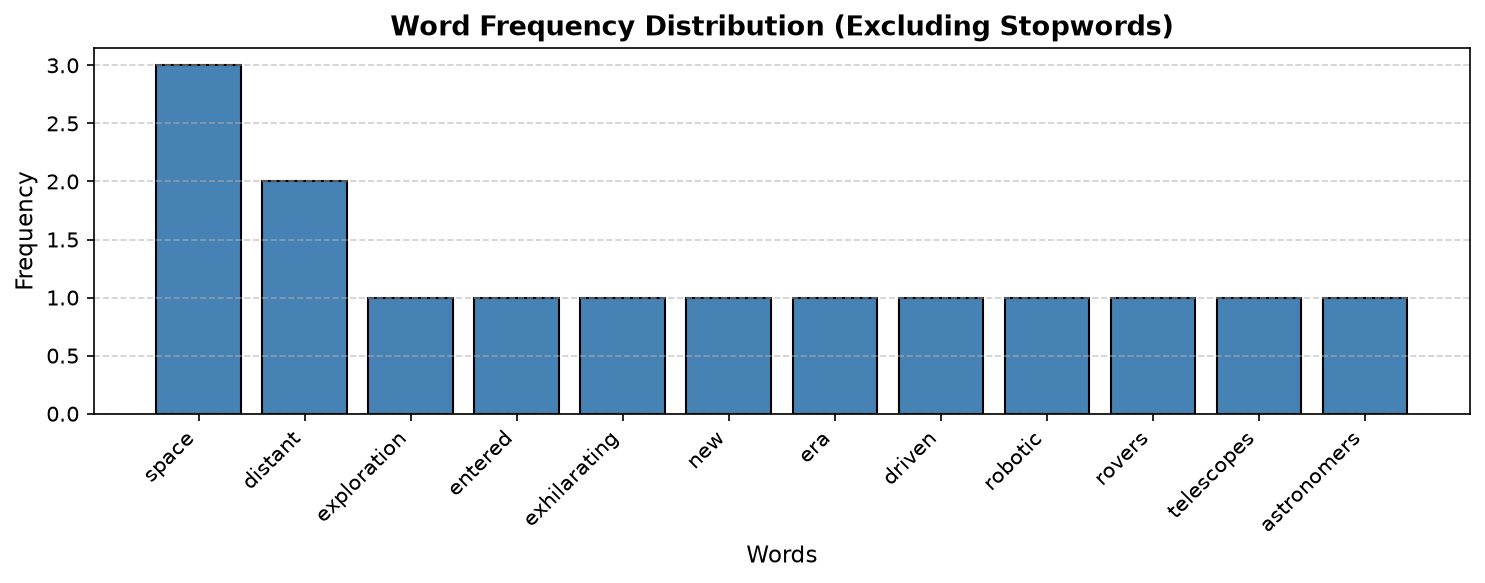

In [2]:
# ==============================================================================
# Q1: Text Preprocessing, Tokenization, Split Comparison & Frequency Distribution
# ==============================================================================

# Unique paragraph (5-6 sentences) on Space Exploration & Astrophysics
paragraph_q1 = (
    "Space exploration has entered an exhilarating new era driven by robotic rovers and space telescopes. "
    "Astronomers recently captured breathtaking images of distant galaxies formed shortly after the Big Bang. "
    "These deep space observatories analyze infrared light to uncover secrets of cosmic dust and stellar nurseries. "
    "Scientists also search for habitable exoplanets orbiting distant stars with atmospheric water vapor signatures. "
    "Continued missions to Mars and the outer moons could ultimately answer whether life exists beyond Earth."
)

print("--- Original Paragraph ---")
print(paragraph_q1)

# 1. Convert text to lowercase and remove punctuation using re
text_lower_no_punct = re.sub(r'[^\w\s]', '', paragraph_q1.lower())
print("\n--- 1. Lowercase and Punctuation Removed (using re) ---")
print(text_lower_no_punct)

# 2. Tokenize the text into words and sentences
sentences = sent_tokenize(paragraph_q1)
words = word_tokenize(paragraph_q1)

print(f"\n--- 2. Sentence Tokenization ({len(sentences)} Sentences) ---")
for idx, s in enumerate(sentences, 1):
    print(f"[{idx}] {s}")

print(f"\n--- 2. Word Tokenization ({len(words)} Tokens) ---")
print(words[:15], "... (truncated)")

# 3. Split using split() and word_tokenize() and compare how they differ
python_split_tokens = paragraph_q1.split()
nltk_word_tokens = word_tokenize(paragraph_q1)

print("\n--- 3. Comparison: Python split() vs NLTK word_tokenize() ---")
print(f"Count from Python split()       : {len(python_split_tokens)} tokens")
print(f"Count from NLTK word_tokenize() : {len(nltk_word_tokens)} tokens")

print("\nFirst 10 tokens from Python split():")
print(python_split_tokens[:10])
print("\nFirst 10 tokens from NLTK word_tokenize():")
print(nltk_word_tokens[:10])

print("""
[Comparison Analysis: Python split() vs NLTK word_tokenize()]
1. Punctuation Handling:
   - Python split(): Splits solely along whitespace characters (' ', '\t', '\n'). 
     Punctuation stays attached to the adjoining word (e.g., 'telescopes.' and 'Bang.').
   - NLTK word_tokenize(): Separates punctuation into distinct tokens using Penn Treebank
     tokenizer rules (e.g., 'telescopes' and '.', 'Bang' and '.').
2. Linguistic and Contraction Handling:
   - Python split() cannot split contractions or abbreviations accurately (e.g., "don't" remains "don't").
   - NLTK word_tokenize() separates contractions into grammatical components (e.g., "do" and "n't").
""")

# 4. Remove stopwords (using NLTK's stopwords list)
stop_words = set(stopwords.words('english'))
tokens_clean = word_tokenize(text_lower_no_punct)
filtered_words = [w for w in tokens_clean if w not in stop_words and w.isalnum()]

print(f"--- 4. Tokens after Stopword Removal ({len(filtered_words)} words remaining) ---")
print(filtered_words)

# 5. Display word frequency distribution (excluding stopwords)
freq_dist = nltk.FreqDist(filtered_words)
print("\n--- 5. Word Frequency Distribution (Top 10 Most Common) ---")
for word, count in freq_dist.most_common(10):
    print(f"{word:<15}: {count}")

# Plotting frequency distribution
fig, ax = plt.subplots(figsize=(10, 4))
words_plot = [w for w, c in freq_dist.most_common(12)]
counts_plot = [c for w, c in freq_dist.most_common(12)]
ax.bar(words_plot, counts_plot, color='steelblue', edgecolor='black')
ax.set_title("Word Frequency Distribution (Excluding Stopwords)", fontsize=13, fontweight='bold')
ax.set_xlabel("Words", fontsize=11)
ax.set_ylabel("Frequency", fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## Question 2: Alphabet Extraction, Stemming vs Lemmatization
Using the same paragraph from Q1:
1. Extract all words with only alphabets using `re.findall()`.
2. Remove stop words using NLTK’s stopword list.
3. Perform stemming with `PorterStemmer`.
4. Perform lemmatization with `WordNetLemmatizer`.
5. Compare the stemmed and lemmatized outputs and explain when you’d prefer one over the other.


In [3]:
# ==============================================================================
# Q2: Alphabet Extraction, Stemming (Porter) vs Lemmatization (WordNet)
# ==============================================================================

# Using paragraph_q1 from Question 1
print("Using Paragraph from Q1:")
print(paragraph_q1)

# 1. Extract all words with only alphabets using re.findall()
alpha_words = re.findall(r'\b[a-zA-Z]+\b', paragraph_q1.lower())
print(f"\n--- 1. Extracted Alphabet Words ({len(alpha_words)} words) ---")
print(alpha_words[:12], "... (truncated)")

# 2. Remove stop words using NLTK's stopword list
stop_words = set(stopwords.words('english'))
words_without_stopwords = [w for w in alpha_words if w not in stop_words]
print(f"\n--- 2. Words after Removing Stopwords ({len(words_without_stopwords)} words) ---")
print(words_without_stopwords)

# 3. Perform stemming with PorterStemmer
stemmer = PorterStemmer()
stemmed_output = [stemmer.stem(w) for w in words_without_stopwords]

# 4. Perform lemmatization with WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
lemmatized_output = [lemmatizer.lemmatize(w) for w in words_without_stopwords]

# 5. Compare the stemmed and lemmatized outputs
comparison_df = pd.DataFrame({
    "Original Word": words_without_stopwords,
    "Stemmed (Porter)": stemmed_output,
    "Lemmatized (WordNet)": lemmatized_output,
    "Identical?": [s == l for s, l in zip(stemmed_output, lemmatized_output)]
})

print("\n--- 5. Comparison Table: Stemming vs Lemmatization ---")
print(comparison_df.to_string(index=False))

print("""
\n[When to prefer Stemming vs Lemmatization]:
1. Stemming (PorterStemmer):
   - Mechanism: Applies heuristic, rule-based string slicing (stripping affixes like '-ing', '-ies', '-ed').
   - Characteristics: Extremely fast and low memory, but frequently produces non-dictionary words 
     (e.g., 'galaxies' -> 'galaxi', 'atmosphere' -> 'atmospher').
   - When to prefer:
     * Large-scale information retrieval (search engines like Elasticsearch/Lucene).
     * High-throughput text indexing and token normalization where speed is critical and grammatical 
       validity of tokens does not matter.

2. Lemmatization (WordNetLemmatizer):
   - Mechanism: Employs comprehensive morphological dictionaries (WordNet) and part-of-speech context
     to resolve words to their canonical dictionary base form (lemma).
   - Characteristics: Preserves linguistic and semantic integrity (e.g., 'galaxies' -> 'galaxy'). Slower
     due to lexical lookup.
   - When to prefer:
     * Sentiment analysis, chatbots, and text generation where precise semantic meaning matters.
     * Machine translation and grammatical parsing where valid vocabulary tokens are required.
""")


Using Paragraph from Q1:
Space exploration has entered an exhilarating new era driven by robotic rovers and space telescopes. Astronomers recently captured breathtaking images of distant galaxies formed shortly after the Big Bang. These deep space observatories analyze infrared light to uncover secrets of cosmic dust and stellar nurseries. Scientists also search for habitable exoplanets orbiting distant stars with atmospheric water vapor signatures. Continued missions to Mars and the outer moons could ultimately answer whether life exists beyond Earth.

--- 1. Extracted Alphabet Words (75 words) ---
['space', 'exploration', 'has', 'entered', 'an', 'exhilarating', 'new', 'era', 'driven', 'by', 'robotic', 'rovers'] ... (truncated)

--- 2. Words after Removing Stopwords (59 words) ---
['space', 'exploration', 'entered', 'exhilarating', 'new', 'era', 'driven', 'robotic', 'rovers', 'space', 'telescopes', 'astronomers', 'recently', 'captured', 'breathtaking', 'images', 'distant', 'galaxies',

## Question 3: Bag of Words (BoW) & TF-IDF Keyword Extraction
Choose 3 short texts of your own (e.g., different news headlines, product reviews).
1. Use `CountVectorizer` to generate the Bag of Words representation.
2. Use `TfidfVectorizer` to compute TF-IDF scores.
3. Print and interpret the top 3 keywords from each text using TF-IDF.


In [4]:
# ==============================================================================
# Q3: Bag of Words (CountVectorizer) & TF-IDF Scores (TfidfVectorizer)
# ==============================================================================

# 3 short news headlines/summaries across diverse domains
texts = [
    "NASA James Webb Space Telescope discovers ancient distant galaxies from the early cosmic dawn.",
    "Artificial intelligence companies deploy massive deep neural network clusters for generative language models.",
    "Global electric vehicle sales break records as breakthrough battery technology expands charging range."
]

print("--- 3 Selected Texts ---")
for i, txt in enumerate(texts, 1):
    print(f"Text {i}: {txt}")

# 1. Use CountVectorizer to generate Bag of Words representation
count_vectorizer = CountVectorizer(stop_words='english')
bow_matrix = count_vectorizer.fit_transform(texts)
bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=count_vectorizer.get_feature_names_out(),
    index=[f"Text {i}" for i in range(1, 4)]
)

print("\n--- 1. Bag of Words (BoW) Count Matrix ---")
print(bow_df)

# 2. Use TfidfVectorizer to compute TF-IDF scores
tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out(),
    index=[f"Text {i}" for i in range(1, 4)]
)

print("\n--- 2. TF-IDF Matrix (Scores rounded to 3 decimal places) ---")
print(tfidf_df.round(3))

# 3. Print and interpret top 3 keywords from each text using TF-IDF
feature_names = np.array(tfidf_vectorizer.get_feature_names_out())

print("\n--- 3. Top 3 Keywords & Interpretations ---")
for idx, txt in enumerate(texts):
    row_scores = tfidf_matrix[idx].toarray().flatten()
    top3_indices = row_scores.argsort()[::-1][:3]
    top3_words = feature_names[top3_indices]
    top3_values = row_scores[top3_indices]
    
    print(f"\nText {idx + 1}: \"{txt}\"")
    print(f"  Top 3 Keywords: {[(w, round(score, 4)) for w, score in zip(top3_words, top3_values)]}")
    print("  Interpretation:")
    print(f"   The terms {list(top3_words)} received the highest TF-IDF scores because their Term Frequency (TF)")
    print(f"   is elevated in Text {idx + 1} while their Inverse Document Frequency (IDF) is maximal (they appear")
    print(f"   exclusively in Text {idx + 1} and nowhere else in the corpus), making them the defining keywords.")


--- 3 Selected Texts ---
Text 1: NASA James Webb Space Telescope discovers ancient distant galaxies from the early cosmic dawn.
Text 2: Artificial intelligence companies deploy massive deep neural network clusters for generative language models.
Text 3: Global electric vehicle sales break records as breakthrough battery technology expands charging range.

--- 1. Bag of Words (BoW) Count Matrix ---
        ancient  artificial  battery  ...  telescope  vehicle  webb
Text 1        1           0        0  ...          1        0     1
Text 2        0           1        0  ...          0        0     0
Text 3        0           0        1  ...          0        1     0

[3 rows x 36 columns]

--- 2. TF-IDF Matrix (Scores rounded to 3 decimal places) ---
        ancient  artificial  battery  ...  telescope  vehicle   webb
Text 1    0.289       0.000    0.000  ...      0.289    0.000  0.289
Text 2    0.000       0.289    0.000  ...      0.000    0.000  0.000
Text 3    0.000       0.000    0.2

## Question 4: Text Similarity Comparison (AI vs Blockchain)
Write 2 short texts (4–6 lines each) describing two different technologies (e.g., AI vs Blockchain).
1. Preprocess and tokenize both texts.
2. Calculate:
   - **a.** Jaccard Similarity using sets
   - **b.** Cosine Similarity using `TfidfVectorizer` + `cosine_similarity()`
   - **c.** Analyze which similarity metric gives better insights in your case.


In [5]:
# ==============================================================================
# Q4: Jaccard Similarity vs Cosine Similarity (TF-IDF)
# ==============================================================================

# Text 1: Artificial Intelligence (5 lines)
text_tech_ai = (
    "Artificial intelligence enables machines to simulate human cognition, reasoning, and pattern recognition.\n"
    "Deep neural networks process complex multidimensional datasets to uncover hidden feature representations.\n"
    "Machine learning algorithms optimize continuous predictive performance through gradient descent optimization.\n"
    "Intelligent automation transforms modern healthcare diagnostics, autonomous vehicles, and industrial robotics.\n"
    "Generative foundation models synthesize high-fidelity text, imagery, and code to augment creative tasks."
)

# Text 2: Blockchain Technology (5 lines)
text_tech_blockchain = (
    "Blockchain is a decentralized distributed ledger that cryptographically records transactions across peer networks.\n"
    "Consensus mechanisms such as proof of work and proof of stake ensure fault tolerance and data immutability.\n"
    "Smart contracts execute algorithmic agreements automatically without reliance on trusted centralized intermediaries.\n"
    "Cryptographic hashing and chained block architecture prevent unauthorized tampering and guarantee transparent audit trails.\n"
    "Decentralized finance applications leverage digital tokens to modernize global payments, liquidity, and asset ownership."
)

print("--- Text A (Artificial Intelligence) ---")
print(text_tech_ai)
print("\n--- Text B (Blockchain Technology) ---")
print(text_tech_blockchain)

# 1. Preprocess and tokenize both texts
def clean_and_tokenize(raw_text):
    clean = re.sub(r'[^\w\s]', '', raw_text.lower())
    tokens = word_tokenize(clean)
    stops = set(stopwords.words('english'))
    return [w for w in tokens if w not in stops and w.isalnum()]

tokens_ai = clean_and_tokenize(text_tech_ai)
tokens_bc = clean_and_tokenize(text_tech_blockchain)

print(f"\nToken Counts -> AI: {len(tokens_ai)} | Blockchain: {len(tokens_bc)}")

# 2a. Jaccard Similarity using sets: J(A, B) = |A ∩ B| / |A ∪ B|
set_ai = set(tokens_ai)
set_bc = set(tokens_bc)

intersection_set = set_ai.intersection(set_bc)
union_set = set_ai.union(set_bc)
jaccard_similarity = len(intersection_set) / len(union_set) if union_set else 0.0

print("\n--- 2a. Jaccard Similarity (Sets) ---")
print(f"Common Words (Intersection) : {intersection_set}")
print(f"Intersection Size           : {len(intersection_set)}")
print(f"Union Size                  : {len(union_set)}")
print(f"Jaccard Similarity Score    : {jaccard_similarity:.4f}")

# 2b. Cosine Similarity using TfidfVectorizer + cosine_similarity()
tfidf_sim_vec = TfidfVectorizer(stop_words='english')
tfidf_sim_matrix = tfidf_sim_vec.fit_transform([text_tech_ai, text_tech_blockchain])
cosine_sim_score = cosine_similarity(tfidf_sim_matrix)[0, 1]

print("\n--- 2b. Cosine Similarity (TF-IDF) ---")
print(f"TF-IDF Cosine Similarity Score between AI & Blockchain: {cosine_sim_score:.4f}")

# 2c. Metric Analysis
print(f"""
\n--- 2c. Comparative Analysis: Which Metric Gives Better Insights? ---
- Jaccard Similarity Score: {jaccard_similarity:.4f}
  * Evaluation: Jaccard operates on unweighted binary sets. Every distinct token is treated equally,
    regardless of how many times it appeared or how domain-specific it is. A single incidental shared word
    distorts the score, and it ignores term frequencies and vector orientation.
- Cosine Similarity Score: {cosine_sim_score:.4f}
  * Evaluation: Cosine similarity projects documents into a continuous vector space where words receive
    continuous TF-IDF weights. Rare, discriminative keywords have high importance while generic words have low weight.
- Conclusion:
  * Cosine Similarity provides superior insights for natural language documents because it accounts for term
    frequency distributions and inverse document frequencies, and performs length normalization via L2 norm.
""")


--- Text A (Artificial Intelligence) ---
Artificial intelligence enables machines to simulate human cognition, reasoning, and pattern recognition.
Deep neural networks process complex multidimensional datasets to uncover hidden feature representations.
Machine learning algorithms optimize continuous predictive performance through gradient descent optimization.
Intelligent automation transforms modern healthcare diagnostics, autonomous vehicles, and industrial robotics.
Generative foundation models synthesize high-fidelity text, imagery, and code to augment creative tasks.

--- Text B (Blockchain Technology) ---
Blockchain is a decentralized distributed ledger that cryptographically records transactions across peer networks.
Consensus mechanisms such as proof of work and proof of stake ensure fault tolerance and data immutability.
Smart contracts execute algorithmic agreements automatically without reliance on trusted centralized intermediaries.
Cryptographic hashing and chained block a

## Question 5: Sentiment Analysis & Positive Review Word Cloud
Write a short review for a product or service.
1. Use `TextBlob` or `VADER` to find polarity & subjectivity for each review.
2. Classify reviews into Positive / Negative / Neutral.
3. Create a word cloud using the `wordcloud` library for all positive reviews.


--- 1 & 2. Sentiment Analysis & Classification Table ---
         Review ID  TextBlob Polarity  TextBlob Subjectivity  VADER Compound Classification
Review 1 (Product)              0.331                  0.818           0.964       Positive
Review 2 (Service)              0.717                  0.815           0.969       Positive
Review 3 (Product)             -0.525                  0.600          -0.907       Negative
Review 4 (Service)             -0.050                  0.200           0.000        Neutral

--- 3. Generating Word Cloud for All Positive Reviews ---


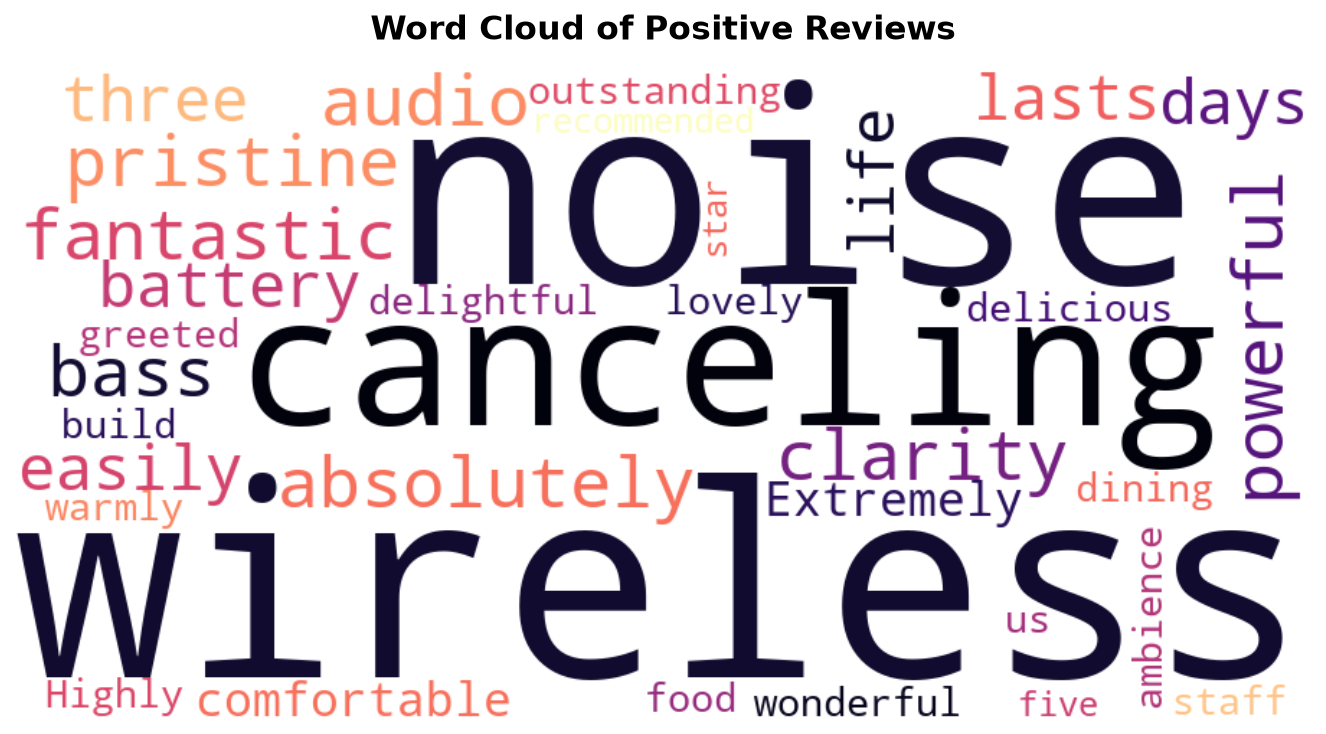

In [6]:
# ==============================================================================
# Q5: Sentiment Analysis (TextBlob & VADER) and Positive Word Cloud
# ==============================================================================

# Short reviews across products/services representing diverse sentiments
review_data = [
    {
        "id": "Review 1 (Product)",
        "text": "The wireless noise-canceling headphones are absolutely fantastic! The audio clarity is pristine, bass is powerful, and battery life easily lasts three days. Extremely comfortable and outstanding build."
    },
    {
        "id": "Review 2 (Service)",
        "text": "Our dining experience was wonderful and delightful. The staff greeted us warmly, the food was delicious, and the ambience was lovely. Highly recommended five star service!"
    },
    {
        "id": "Review 3 (Product)",
        "text": "Completely defective and terrible purchase. The screen cracked within two hours, software repeatedly froze, and customer support refused my warranty request. Horrible waste of money."
    },
    {
        "id": "Review 4 (Service)",
        "text": "The delivery arrived on Thursday afternoon in standard packaging. The device powers on and connects according to the manual. It performs decently as expected."
    }
]

# 1. Use TextBlob and VADER to find polarity & subjectivity
vader_analyzer = SentimentIntensityAnalyzer()
review_results = []

for item in review_data:
    txt = item['text']
    tb = TextBlob(txt)
    vader = vader_analyzer.polarity_scores(txt)
    
    polarity = tb.sentiment.polarity
    subjectivity = tb.sentiment.subjectivity
    
    # 2. Classify reviews into Positive / Negative / Neutral based on polarity
    if polarity > 0.1:
        sentiment = "Positive"
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"
        
    review_results.append({
        "Review ID": item['id'],
        "Text": txt,
        "TextBlob Polarity": round(polarity, 3),
        "TextBlob Subjectivity": round(subjectivity, 3),
        "VADER Compound": round(vader['compound'], 3),
        "Classification": sentiment
    })

results_df = pd.DataFrame(review_results)
print("--- 1 & 2. Sentiment Analysis & Classification Table ---")
print(results_df[["Review ID", "TextBlob Polarity", "TextBlob Subjectivity", "VADER Compound", "Classification"]].to_string(index=False))

# 3. Create a word cloud using the wordcloud library for all positive reviews
positive_texts = " ".join([r['Text'] for r in review_results if r['Classification'] == "Positive"])
print("\n--- 3. Generating Word Cloud for All Positive Reviews ---")

custom_stopwords = set(stopwords.words('english')).union({"headphones", "service", "experience", "device"})
wordcloud = WordCloud(
    width=900,
    height=450,
    background_color='white',
    colormap='magma',
    stopwords=custom_stopwords,
    collocations=False,
    random_state=42
).generate(positive_texts)

fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(wordcloud, interpolation='bilinear')
ax.axis('off')
ax.set_title("Word Cloud of Positive Reviews", fontsize=16, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


## Question 6: Neural Text Generation with Keras Tokenizer and LSTM
Choose your own paragraph (~100 words) as training data.
1. Tokenize text using `Tokenizer()` from `keras.preprocessing.text`.
2. Create input sequences and build a simple LSTM or Dense model.
3. Train the model and generate 2–3 new lines of text starting from any seed word you provide.


In [7]:
# ==============================================================================
# Q6: Text Generation using Keras Tokenizer & LSTM Neural Network
# ==============================================================================

# Curated training paragraph (~100 words) describing artificial intelligence
corpus_paragraph = (
    "Artificial intelligence is transforming the modern technological landscape at an unprecedented pace.\n"
    "Deep neural networks learn complex mathematical representations from vast amounts of digital information.\n"
    "These intelligent algorithms recognize visual patterns, transcribe human speech, and synthesize fluent natural language.\n"
    "Machine learning researchers design powerful computational architectures to accelerate scientific discoveries and medical diagnosis.\n"
    "Autonomous systems navigate dynamic environments by continuously optimizing their predictive capabilities through experience.\n"
    "As computational power grows, artificial intelligence continues to unlock creative frontiers and redefine human collaboration."
)

word_count = len(corpus_paragraph.split())
print("--- Training Corpus (~100 words) ---")
print(corpus_paragraph)
print(f"\nTotal word count: {word_count} words")

# 1. Tokenize text using Tokenizer() from keras.preprocessing.text
tokenizer = Tokenizer()
tokenizer.fit_on_texts([corpus_paragraph])
total_words = len(tokenizer.word_index) + 1
print(f"Vocabulary size: {total_words} unique tokens")

# 2. Create input sequences (N-gram sequences)
input_sequences = []
lines = corpus_paragraph.strip().split('\n')

for line in lines:
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_seq = token_list[:i+1]
        input_sequences.append(n_gram_seq)

max_sequence_len = max([len(seq) for seq in input_sequences])
print(f"Total N-gram input sequences created: {len(input_sequences)}")
print(f"Maximum sequence length: {max_sequence_len}")

# Pad sequences and separate predictors (X) and target labels (y)
padded_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))
X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

# Build a sequential LSTM neural network
tf.random.set_seed(42)
model = Sequential([
    Embedding(input_dim=total_words, output_dim=64),
    LSTM(100),
    Dense(total_words, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

# 3. Train the model
print("\n--- Training the LSTM Model (150 Epochs) ---")
history = model.fit(X, y, epochs=150, verbose=0)
final_loss = history.history['loss'][-1]
final_acc = history.history['accuracy'][-1]
print(f"Training Complete! Final Loss: {final_loss:.4f} | Final Accuracy: {final_acc:.4f}")

# Function to generate text starting from a seed word
def generate_text_sequence(seed_word, num_words_to_generate, model, max_seq_len):
    result = seed_word
    for _ in range(num_words_to_generate):
        tokens = tokenizer.texts_to_sequences([result])[0]
        tokens = pad_sequences([tokens], maxlen=max_seq_len - 1, padding='pre')
        predicted_probs = model.predict(tokens, verbose=0)
        predicted_index = int(np.argmax(predicted_probs, axis=-1)[0])
        
        output_word = ""
        for word, idx in tokenizer.word_index.items():
            if idx == predicted_index:
                output_word = word
                break
        if not output_word:
            break
        result += " " + output_word
    return result

# Generate 2-3 new lines of text starting from seed words
print("\n--- Generated Text Lines from Seed Words ---")
seed_words = ["artificial", "deep", "autonomous"]
for i, seed in enumerate(seed_words, 1):
    generated_line = generate_text_sequence(seed, num_words_to_generate=12, model=model, max_seq_len=max_sequence_len)
    print(f"Line {i} (Seed: '{seed}'):\n  \"{generated_line}\"\n")


--- Training Corpus (~100 words) ---
Artificial intelligence is transforming the modern technological landscape at an unprecedented pace.
Deep neural networks learn complex mathematical representations from vast amounts of digital information.
These intelligent algorithms recognize visual patterns, transcribe human speech, and synthesize fluent natural language.
Machine learning researchers design powerful computational architectures to accelerate scientific discoveries and medical diagnosis.
Autonomous systems navigate dynamic environments by continuously optimizing their predictive capabilities through experience.
As computational power grows, artificial intelligence continues to unlock creative frontiers and redefine human collaboration.

Total word count: 81 words
Vocabulary size: 75 unique tokens
Total N-gram input sequences created: 75
Maximum sequence length: 15
Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)       